#Tabular Project for DATA4380-001

Haruka Zambeck, Oluwateniola Talabi, Reel Elsadig, Aya Hassan

In [ ]:
# OBJECTIVE: Predicting sleep disorder risk based on lifestyle.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import zipfile

with zipfile.ZipFile('archive.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

 #Data Understanding

In [ ]:
df = pd.read_csv("Sleep_health_and_lifestyle_dataset.csv")
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


In [ ]:
df.notnull().sum()

,0
Person ID,374
Gender,374
Age,374
Occupation,374
Sleep Duration,374
Quality of Sleep,374
Physical Activity Level,374
Stress Level,374
BMI Category,374
Blood Pressure,374


not too worried about the nulls in sleep disorders null because just means sleep disorder for patient doesn't exist

the tail having the same results for many rows is concerning, but we can't tell if it's actually a duplicate or coincidentally the same. just in case, we will keep it. my guess -> random oversampling to combat imbalance. How many people do y'all know who has sleep apnea? some study says 32.4% out of 83.7 million.

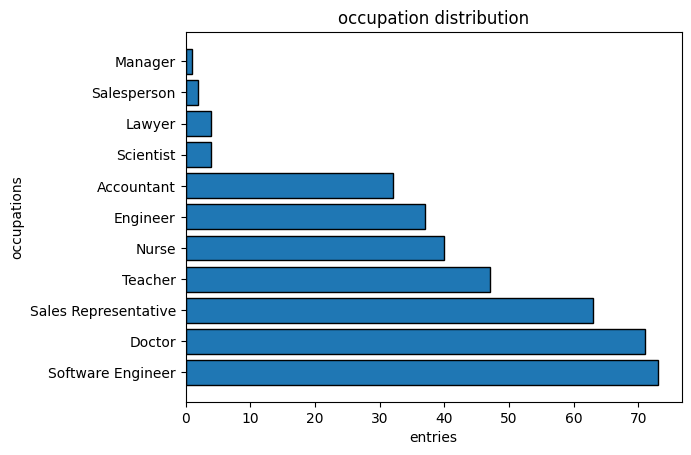

In [ ]:
occupation_count = df['Occupation'].value_counts()

plt.barh(df['Occupation'].unique(), occupation_count, edgecolor='black')
plt.title('occupation distribution')
plt.xlabel('entries')
plt.ylabel('occupations')
plt.show()

In [ ]:
df.value_counts('Occupation')

,count
Occupation,
Nurse,73
Doctor,71
Engineer,63
Lawyer,47
Teacher,40
Accountant,37
Salesperson,32
Scientist,4
Software Engineer,4


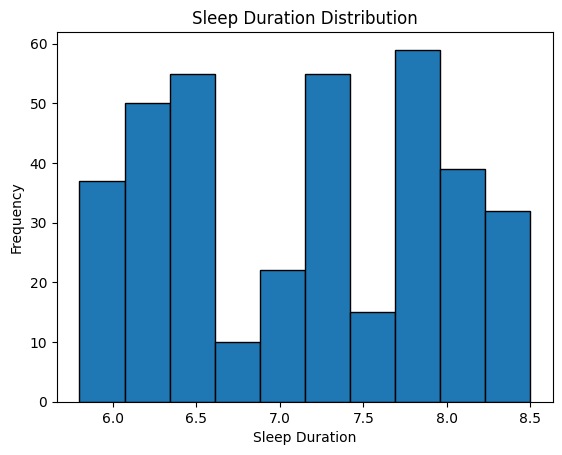

In [ ]:
plt.hist(df['Sleep Duration'], bins=10, edgecolor='black')

plt.title('Sleep Duration Distribution')
plt.xlabel('Sleep Duration')
plt.ylabel('Frequency')
plt.show()


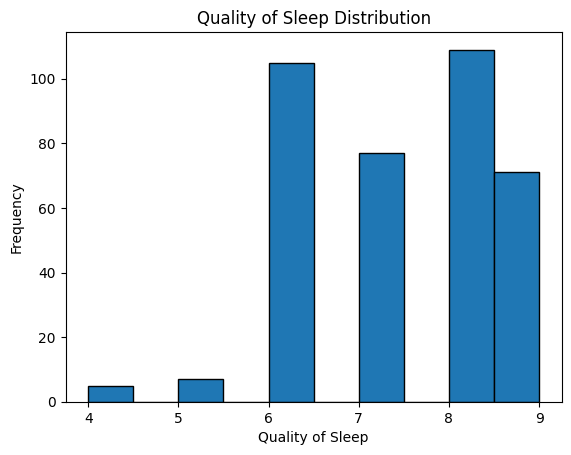

In [ ]:
plt.hist(df['Quality of Sleep'], bins=10, edgecolor='black')

plt.title('Quality of Sleep Distribution')
plt.xlabel('Quality of Sleep')
plt.ylabel('Frequency')
plt.show()


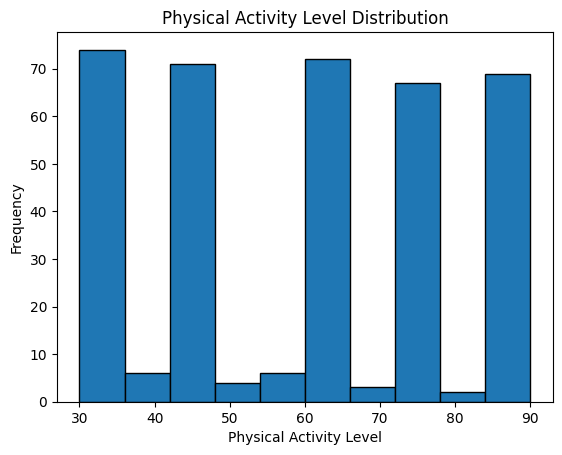

In [ ]:
plt.hist(df['Physical Activity Level'], bins=10, edgecolor='black')

plt.title('Physical Activity Level Distribution')
plt.xlabel('Physical Activity Level')
plt.ylabel('Frequency')
plt.show()

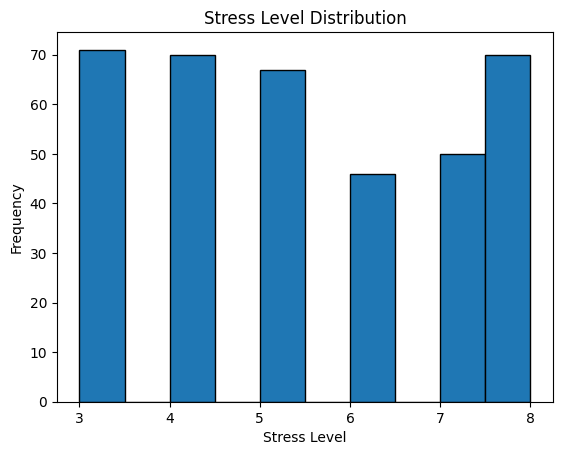

In [ ]:
plt.hist(df['Stress Level'], bins=10, edgecolor='black')

plt.title('Stress Level Distribution')
plt.xlabel('Stress Level')
plt.ylabel('Frequency')
plt.show()

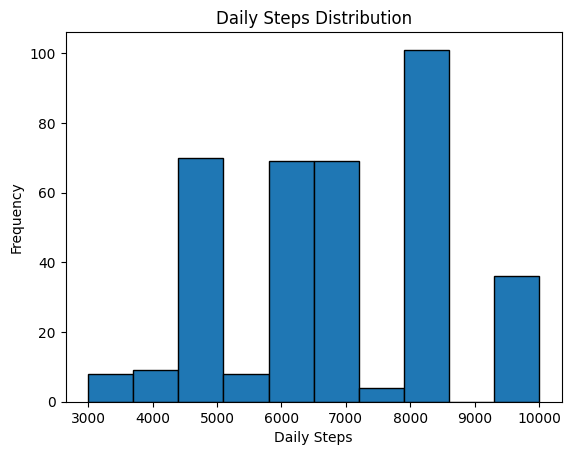

In [ ]:
plt.hist(df['Daily Steps'], bins=10, edgecolor='black')

plt.title('Daily Steps Distribution')
plt.xlabel('Daily Steps')
plt.ylabel('Frequency')
plt.show()


In [ ]:
unique_sleep_disorders = df['Sleep Disorder'].unique()
print(unique_sleep_disorders)

[nan 'Sleep Apnea' 'Insomnia']


In [ ]:
df.value_counts('Sleep Disorder').unique()

array([78, 77])

ANOMALY = dupllicate like entries. Keeping because imbalance and the distribution doesn't look like it was effected too much.
MISSING VALUES = present in sleep disorders. indicating a lack of sleep disorder in patient

#Data Preprocessing

- I want a new feature that takes the sleeporders and make it binary 0- no disorder 1- disorder present

- life style factors I want to compare against disorder existence: occupation, sleep duration, stress level, physical activity level, daily steps,

- don't want to use sleep quality bc it will predict based on that alone... data leakage risk

In [ ]:
# dropping health and demographic features as well as quality of sleep

df_lifestyle = df.drop(['Gender', 'Age', 'Quality of Sleep', 'Blood Pressure', "BMI Category" , 'Heart Rate'] , axis=1)
df_lifestyle.head()

,Person ID,Occupation,Sleep Duration,Physical Activity Level,Stress Level,Daily Steps,Sleep Disorder
0,1,Software Engineer,6.1,42,6,4200,NaN
1,2,Doctor,6.2,60,8,10000,NaN
2,3,Doctor,6.2,60,8,10000,NaN
3,4,Sales Representative,5.9,30,8,3000,Sleep Apnea
4,5,Sales Representative,5.9,30,8,3000,Sleep Apnea


In [ ]:
## label encoding

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df_lifestyle['Occupation'] = label_encoder.fit_transform(df_lifestyle['Occupation'])

df_lifestyle.head()

,Person ID,Occupation,Sleep Duration,Physical Activity Level,Stress Level,Daily Steps,Sleep Disorder
0,1,9,6.1,42,6,4200,NaN
1,2,1,6.2,60,8,10000,NaN
2,3,1,6.2,60,8,10000,NaN
3,4,6,5.9,30,8,3000,Sleep Apnea
4,5,6,5.9,30,8,3000,Sleep Apnea


In [ ]:
print(dict(enumerate(label_encoder.classes_)))

{0: 'Accountant', 1: 'Doctor', 2: 'Engineer', 3: 'Lawyer', 4: 'Manager', 5: 'Nurse', 6: 'Sales Representative', 7: 'Salesperson', 8: 'Scientist', 9: 'Software Engineer', 10: 'Teacher'}


In [ ]:
# Converting sleep disorder to 0 = no disorder and 1= yes disorder

df_lifestyle['Sleep Disorder'] = df_lifestyle['Sleep Disorder'].apply(lambda x: 0 if pd.isna(x) or x == 'NaN' else 1)

In [ ]:
df_lifestyle.head()

,Person ID,Occupation,Sleep Duration,Physical Activity Level,Stress Level,Daily Steps,Sleep Disorder
0,1,9,6.1,42,6,4200,0
1,2,1,6.2,60,8,10000,0
2,3,1,6.2,60,8,10000,0
3,4,6,5.9,30,8,3000,1
4,5,6,5.9,30,8,3000,1


# EDA

In [ ]:
# EDA

df_eda = df_lifestyle.drop(columns=['Person ID'], errors='ignore')

numeric_df = df_eda.select_dtypes(include='number')

correlation_matrix = numeric_df.corr()
print(correlation_matrix)

                         Occupation  Sleep Duration  Physical Activity Level  \
Occupation                 1.000000       -0.325775                -0.103660   
Sleep Duration            -0.325775        1.000000                 0.212360   
Physical Activity Level   -0.103660        0.212360                 1.000000   
Stress Level               0.021123       -0.811023                -0.034134   
Daily Steps               -0.105877       -0.039533                 0.772723   
Sleep Disorder             0.580162       -0.338622                 0.069787   

                         Stress Level  Daily Steps  Sleep Disorder  
Occupation                   0.021123    -0.105877        0.580162  
Sleep Duration              -0.811023    -0.039533       -0.338622  
Physical Activity Level     -0.034134     0.772723        0.069787  
Stress Level                 1.000000     0.186829        0.181685  
Daily Steps                  0.186829     1.000000       -0.026575  
Sleep Disorder           

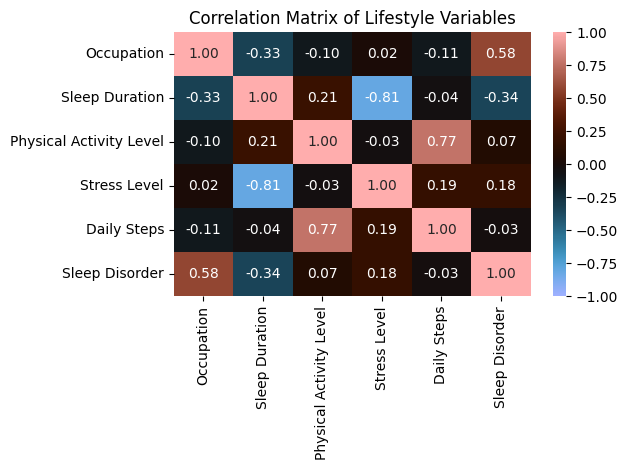

In [ ]:
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='berlin',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlation Matrix of Lifestyle Variables')
plt.tight_layout()
plt.show()

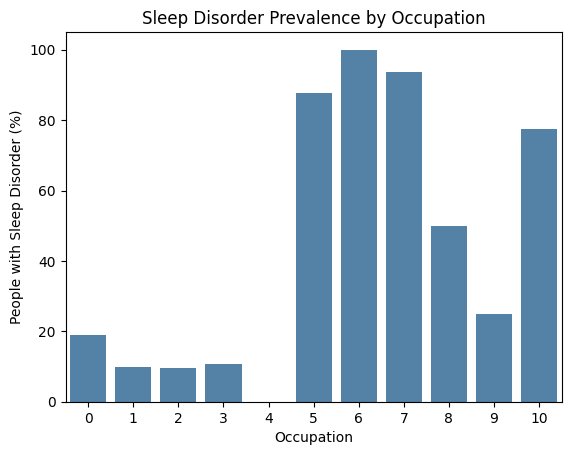

In [ ]:
# Calculate the percentage with a sleep disorder for each occupation
prevalence = (df_lifestyle.groupby('Occupation')['Sleep Disorder'].mean().mul(100).reset_index(name='Prevalence (%)'))

sns.barplot(data=prevalence,x='Occupation',y='Prevalence (%)',color='steelblue')

plt.title('Sleep Disorder Prevalence by Occupation')
plt.xlabel('Occupation')
plt.ylabel('People with Sleep Disorder (%)')
plt.show()

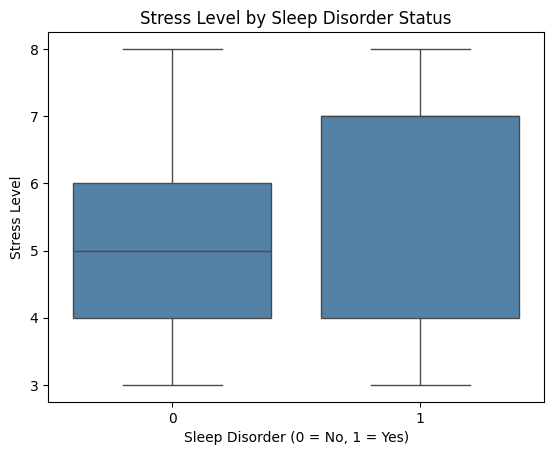

In [ ]:
sns.boxplot(data=df_lifestyle, x='Sleep Disorder', y='Stress Level', color = 'steelblue')

plt.title('Stress Level by Sleep Disorder Status')
plt.xlabel('Sleep Disorder (0 = No, 1 = Yes)')
plt.ylabel('Stress Level')
plt.show()

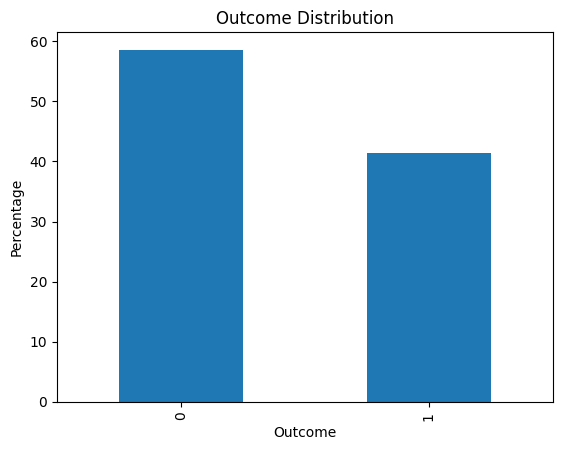

In [ ]:
## imbalance?

outcomes = df_lifestyle["Sleep Disorder"].value_counts() / len(df) * 100
outcomes.plot(kind="bar")
plt.title("Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Percentage")
plt.show()

a little imbalanced.


# 3. Feature Engineering & Preparation
# In this section, we construct new interaction metrics to capture combined
# lifestyle strain and physical activity efficiency relative to daily habits.
# We also scale continuous features to prepare them for modeling.

In [ ]:


# Create an activity-to-step efficiency ratio
df_lifestyle['Step_Activity_Ratio'] = df_lifestyle['Daily Steps'] / (df_lifestyle['Physical Activity Level'] + 1)

# Create a lifestyle strain index (Stress level weighted against sleep duration)
df_lifestyle['Strain_Index'] = df_lifestyle['Stress Level'] / df_lifestyle['Sleep Duration']

df_lifestyle.head()

,Person ID,Occupation,Sleep Duration,Physical Activity Level,Stress Level,Daily Steps,Sleep Disorder,Step_Activity_Ratio,Strain_Index
0,1,9,6.1,42,6,4200,0,97.674419,0.983607
1,2,1,6.2,60,8,10000,0,163.934426,1.290323
2,3,1,6.2,60,8,10000,0,163.934426,1.290323
3,4,6,5.9,30,8,3000,1,96.774194,1.355932
4,5,6,5.9,30,8,3000,1,96.774194,1.355932


engineers new features like step efficiency and lifestyle strain ratios:


# 4. Data Splitting & Scaling
# ==========================================
# Splitting the features (X) and the binary target (y) into training and
# testing sets. We apply stratification to preserve the class balance
# across splits, followed by standard scaling on continuous variables.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_lifestyle.drop(columns=['Person ID', 'Sleep Disorder'])
y = df_lifestyle['Sleep Disorder']

# Stratify by 'y' to maintain the class distribution ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
continuous_cols = [
    'Sleep Duration',
    'Physical Activity Level',
    'Stress Level',
    'Daily Steps',
    'Step_Activity_Ratio',
    'Strain_Index'
]

X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test[continuous_cols] = scaler.transform(X_test[continuous_cols])

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Training features shape: (299, 7)
Testing features shape: (75, 7)


scales your data to prepare it for machine learning training.

# ==========================================
# 5. Model Training & Evaluation
# ==========================================
# Training a Random Forest classifier using our scaled features
# and evaluating its performance on the test set.


Model Accuracy: 0.9467

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95        44
           1       0.94      0.94      0.94        31

    accuracy                           0.95        75
   macro avg       0.95      0.95      0.95        75
weighted avg       0.95      0.95      0.95        75



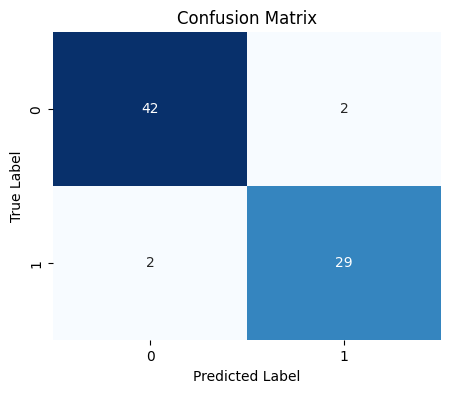

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Initialize and train the model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = rf_model.predict(X_test)

# Evaluate results
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

trains a Random Forest classifier on your processed training data and evaluates its performance on the test set.

# ==========================================
# 6. Feature Importance Analysis
# ==========================================
# Extracting and visualizing which features contributed
# the most to the Random Forest model's predictions.

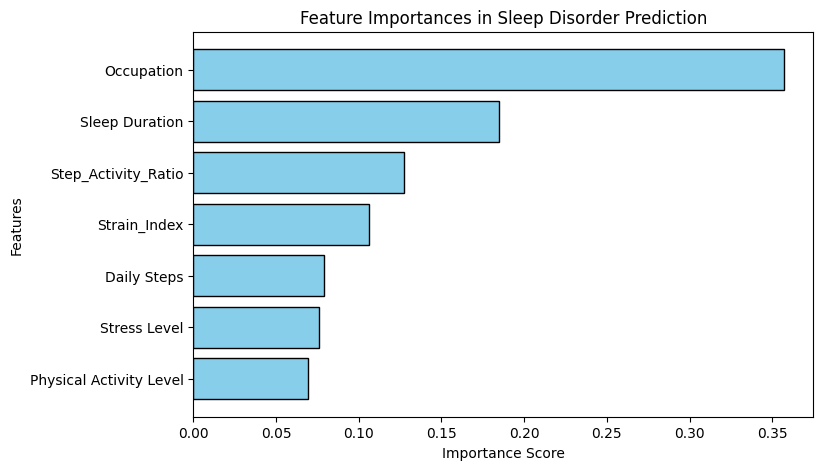

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importances from the trained model
importances = rf_model.feature_importances_
feature_names = X_train.columns

# Create a DataFrame for visualization
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# Plot feature importances
plt.figure(figsize=(8, 5))
plt.barh(feature_imp_df['Feature'], feature_imp_df['Importance'], color='skyblue', edgecolor='black')
plt.title('Feature Importances in Sleep Disorder Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

It extracts feature importance scores from the trained model and plots them horizontally to show which lifestyle variables had the biggest impact on predicting sleep disorders.

# ==========================================
# 7. Model Comparison (Logistic Regression)
# ==========================================
# Training a Logistic Regression model to compare
# performance against our Random Forest classifier.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Initialize and train Logistic Regression
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train, y_train)

# Predict and evaluate
lr_pred = lr_model.predict(X_test)
lr_accuracy = accuracy_score(y_test, lr_pred)

print(f"Logistic Regression Accuracy: {lr_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, lr_pred))

Logistic Regression Accuracy: 0.7333

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.84      0.79        44
           1       0.72      0.58      0.64        31

    accuracy                           0.73        75
   macro avg       0.73      0.71      0.72        75
weighted avg       0.73      0.73      0.73        75



evaluates it to compare its performance against your Random Forest model.

The Result: It achieved an accuracy of 73.33% (significantly lower than Random Forest's ~94.67%).

# 8. Model Comparison (XGBoost)
# ==========================================
# Training an XGBoost classifier to test gradient
# boosting performance against our previous models.

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Initialize and train XGBoost
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

# Predict and evaluate
xgb_pred = xgb_model.predict(X_test)
xgb_accuracy = accuracy_score(y_test, xgb_pred)

print(f"XGBoost Accuracy: {xgb_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, xgb_pred))

XGBoost Accuracy: 0.9600

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97        44
           1       0.97      0.94      0.95        31

    accuracy                           0.96        75
   macro avg       0.96      0.96      0.96        75
weighted avg       0.96      0.96      0.96        75



This cell trains an XGBoost (Extreme Gradient Boosting) classifier and evaluates it.

The Result: It achieved the highest accuracy yet at 96.00% (surpassing Random Forest's 94.67% and Logistic Regression's 73.33%).

# ==========================================
# 9. XGBoost Feature Importance
# ==========================================
# Visualizing which features had the highest
# predictive power in our winning XGBoost model.

<Figure size 800x500 with 0 Axes>

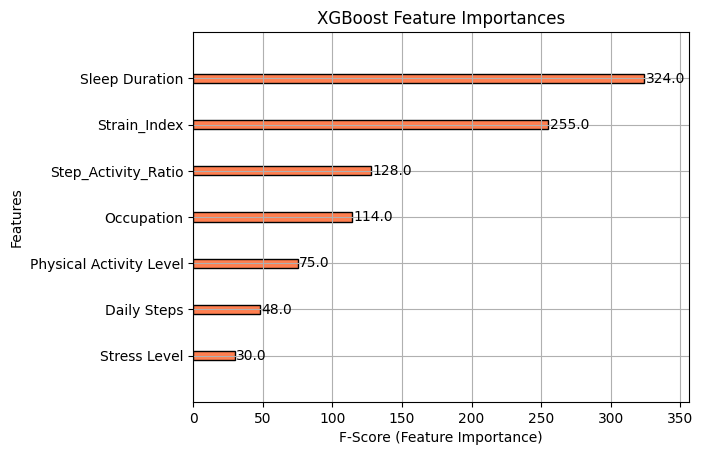

In [ ]:
import matplotlib.pyplot as plt
from xgboost import plot_importance

plt.figure(figsize=(8, 5))
plot_importance(xgb_model, importance_type='weight', color='coral', edgecolor='black')
plt.title('XGBoost Feature Importances')
plt.xlabel('F-Score (Feature Importance)')
plt.ylabel('Features')
plt.show()

visualize feature importances for XGBoost or plot an ROC-AUC curve to evaluate how well your model balances true
positives and false positives.

# ==========================================
# 10. ROC-AUC Curve Evaluation
# ==========================================
# Plotting the Receiver Operating Characteristic curves
# to compare our trained models.

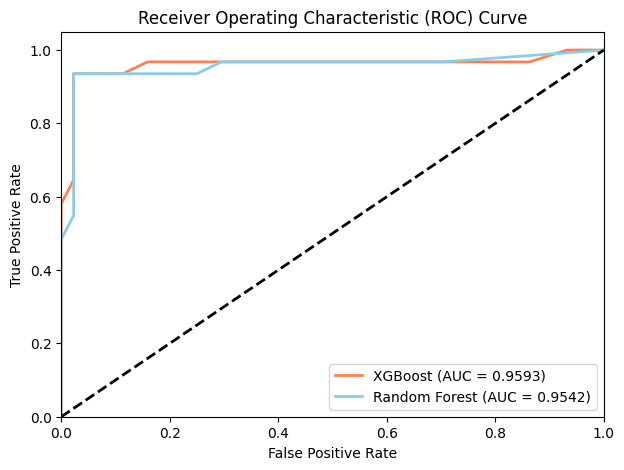

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Compute probabilities for XGBoost and Random Forest
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
rf_probs = rf_model.predict_proba(X_test)[:, 1]

xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)

xgb_auc = auc(xgb_fpr, xgb_tpr)
rf_auc = auc(rf_fpr, rf_tpr)

# Plot curves
plt.figure(figsize=(7, 5))
plt.plot(xgb_fpr, xgb_tpr, label=f'XGBoost (AUC = {xgb_auc:.4f})', color='coral', lw=2)
plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.4f})', color='skyblue', lw=2)
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

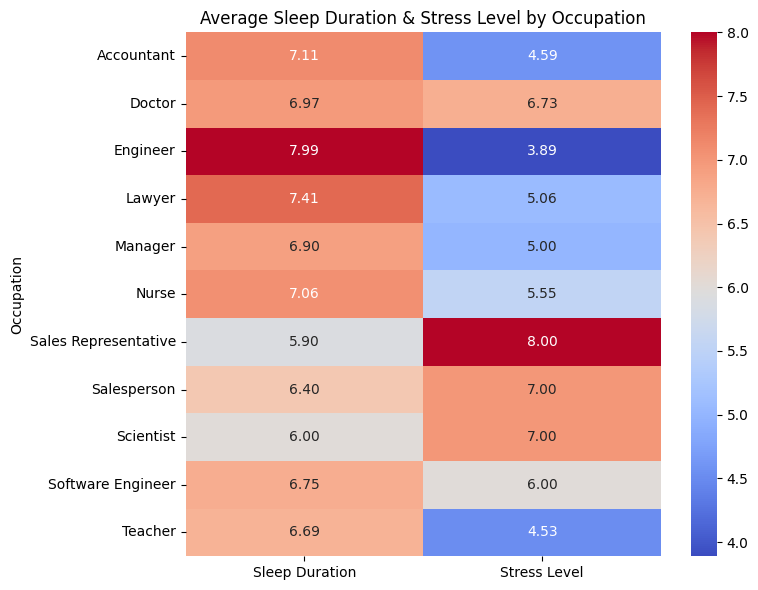

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

try:
    # Load the original dataset to retrieve text-based occupation names
    if 'df' in globals():
        plot_df = df.copy()
    else:
        plot_df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

    # Group by Occupation to show average Sleep Duration and Stress Level for each profession
    grouped_df = plot_df.groupby('Occupation')[['Sleep Duration', 'Stress Level']].mean()

    # Plot a heatmap comparing average values across occupations
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        grouped_df,
        annot=True,
        cmap='coolwarm',
        fmt='.2f'
    )
    plt.title('Average Sleep Duration & Stress Level by Occupation')
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"An error occurred while loading or plotting: {e}")